In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

In [3]:
boston = fetch_openml(name='boston', version=1, as_frame=True, parser='auto')
X = boston.data.astype(float)
y = boston.target.astype(float)

In [4]:
print(X.shape, y.shape)

(506, 13) (506,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

In [11]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'MAE': mean_absolute_error(y_true, y_hat),
        'MAPE (%)': mean_absolute_percentage_error(y_true, y_hat) * 100,
        'R²': r2_score(y_true, y_hat)
    }

In [12]:
metrics_table = pd.DataFrame({
    'Train': regression_metrics(y_train, rf.predict(X_train)),
    'Test': regression_metrics(y_test, y_pred)
})
display(metrics_table)

,Train,Test
MSE,1.978393,7.901514
RMSE,1.406553,2.810963
MAE,0.903478,2.039539
MAPE (%),4.536842,11.092742
R²,0.977227,0.892253


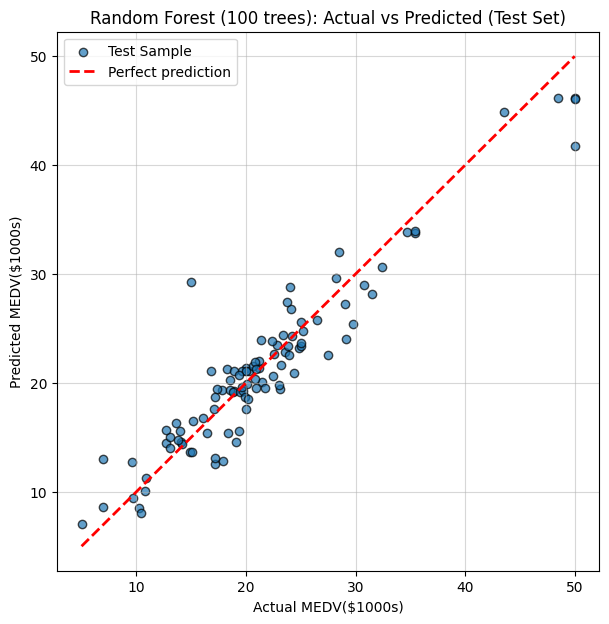

In [15]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor='k', label='Test Sample')

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')

plt.xlabel('Actual MEDV($1000s)')
plt.ylabel('Predicted MEDV($1000s)')
plt.title('Random Forest (100 trees): Actual vs Predicted (Test Set)')
plt.legend()
plt.grid(alpha=0.5)
plt.show()

In [29]:
results = []
for n in [50, 100, 200]:
    model = RandomForestRegressor(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        'Number of Trees': n,
        'Test RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'Test R²': r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Number of Trees,Test RMSE,Test R²
0,50,2.7325,0.8982
1,100,2.8110,0.8923
2,200,2.9172,0.8840


In [30]:
results_df['Test RMSE ($)'] = results_df['Test RMSE'] * 1000
display(results_df.round(4))

,Number of Trees,Test RMSE,Test R²,Test RMSE ($)
0,50,2.7325,0.8982,2732.4753
1,100,2.8110,0.8923,2810.9632
2,200,2.9172,0.8840,2917.2249


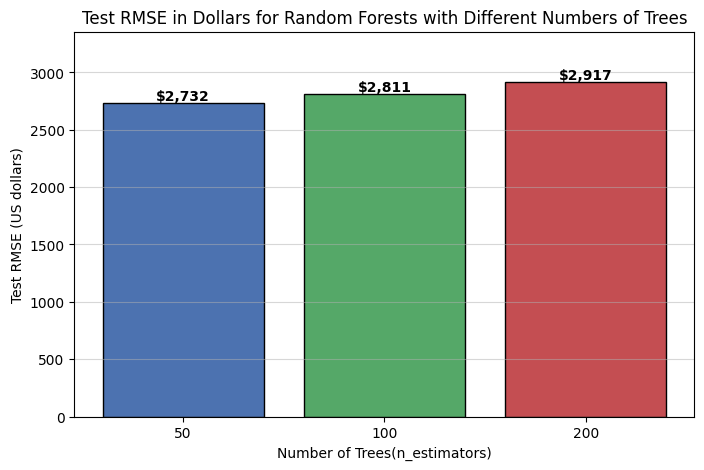

In [32]:
plt.figure(figsize=(8,5))
bars = plt.bar(results_df['Number of Trees'].astype(str),
               results_df['Test RMSE ($)'],
               color=['#4C72B0', '#55A868', '#C44E52'], edgecolor='k')

for bar, val in zip(bars, results_df['Test RMSE ($)']):
    plt.text(bar.get_x() + bar.get_width() / 2, val, f'${val:,.0f}',
             ha='center', va='bottom', fontweight='bold')

plt.xlabel('Number of Trees(n_estimators)')
plt.ylabel('Test RMSE (US dollars)')
plt.title('Test RMSE in Dollars for Random Forests with Different Numbers of Trees')
plt.ylim(0, results_df['Test RMSE ($)'].max() * 1.15)
plt.grid(axis='y', alpha=0.5)
plt.show()

## Analysis of the Effect of the Number of Trees

| Number of Trees | Test RMSE | Test R² | Test RMSE ($) |
|:---:|:---:|:---:|:---:|
| 50 | 2.7325 | 0.8982 | 2,732 |
| 100 | 2.8110 | 0.8923 | 2,811 |
| 200 | 2.9172 | 0.8840 | 2,917 |

**Observation:** The model with 50 trees yields the lowest error ($RMSE \approx \$2,732$) and the highest $R^2$ (0.8982). As the number of trees increases to 100 and 200, the error rises slightly. The difference between the best and worst-performing models is approximately $185 (less than 7% of the RMSE), with an $R^2$ variance of about 0.014.

**Interpretation:** Theoretically, adding more trees to a Random Forest reduces model variance, and the error typically either decreases or stabilizes at a constant level. Therefore, this slight increase in error should not be interpreted as larger forests being "worse." A likely explanation is that the differences are marginal, and the test set contains only about 100 samples; consequently, a few outliers—for instance, a case where the actual price was around 15 but the prediction was around 29—can easily shift the RMSE. Furthermore, since each forest configuration generates a different set of random trees, some of the observed variation is simply due to randomness. **Conclusion:** In this dataset, increasing the number of trees from 50 to 200 did not yield a significant improvement; all three models exhibit nearly identical performance ($R^2 \approx 0.88$ to $0.90$, with an error of approximately $2,700 to $2,900). Consequently, the model with 50 trees is a more efficient choice—offering faster training and prediction times, as well as lower memory usage—while maintaining the same level of quality. For a more definitive conclusion, cross-validation should be employed rather than relying on a single train/test split.